# Масштабируемость и обобщение на большее число пользователей

Дополнение к основному ноутбуку [solution.ipynb](solution.ipynb). Основные эксперименты сделаны на сэмпле 100 тыс. пользователей. Здесь два вопроса:

1. **Масштабируемость.** Как растут время расчёта кандидатов, признаков и обучения LightGBM с числом пользователей, вплоть до полного датасета?
2. **Обобщение.** Сохраняются ли выводы основного ноутбука на других размерах выборки: жадный набор сопоставим с ручным, LLM-набор хуже, объединение даёт небольшой прирост?

Наборы признаков заморожены: это наборы, найденные поиском на сэмпле 100 тыс. (`cache/search_*.json`). Поиск заново не запускается. Для каждого размера выполняется тот же код, что в основном ноутбуке: он берётся прямо из `solution.ipynb`, меняется только `N_USERS`. Протокол оценки тот же, что в разделе 6: число деревьев по `train → val`, переобучение на неделе `val`, оценка на тестовой неделе 16–22.08, `seed` LightGBM 42.

Ноутбук рассчитан на Kaggle (Internet: On): там достаточно памяти для полного датасета.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

ON_KAGGLE = Path('/kaggle/input').exists()
if ON_KAGGLE:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'polars==2.0.0', 'duckdb==2.0.0',
                    'lightgbm==4.7.0', 'openai', 'python-dotenv'], check=True)
    repo = Path('/kaggle/working/recsys-auto-features')
    if not repo.exists():
        subprocess.run(['git', 'clone', '--depth', '1',
                        'https://github.com/404iq/recsys-auto-features.git', str(repo)], check=True)
    os.chdir(repo)
    found = list(Path('/kaggle/input').rglob('interactions.csv'))
    if found:
        os.environ['KION_DATA_DIR'] = str(found[0].parent)
    else:
        url = 'https://github.com/irsafilo/KION_DATASET/raw/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original.zip'
        subprocess.run(['wget', '-q', url, '-O', 'kion.zip'], check=True)
        subprocess.run(['unzip', '-q', '-j', '-o', 'kion.zip', 'data_original/*.csv', '-d', 'data'], check=True)

Cloning into '/kaggle/working/recsys-auto-features'...


Код основного ноутбука. Берём ячейки, которые определяют данные, сэмпл, разбиение, кандидатов, движок признаков, ручной набор и LightGBM. Пропускаем EDA, графики, тест на утечки, перебор `num_leaves` и сами поиски: `num_leaves` фиксируем равным значению, выбранному в основном ноутбуке.

In [2]:
import gc
import json
import time

try:
    import resource                  # пиковая память процесса; модуль есть только на Linux (Kaggle)
except ImportError:
    resource = None

import numpy as np

SIZES = [10_000, 30_000, 100_000, 300_000, 962_179]   # последний — все пользователи датасета
NUM_LEAVES = 31                                       # выбрано в разделе 3.5 основного ноутбука
if not ON_KAGGLE:
    SIZES = [int(x) for x in os.environ.get('SCAL_SIZES', '5000,10000').split(',')]

nb = json.load(open('solution.ipynb', encoding='utf-8'))
code_cells = [''.join(c['source']) for c in nb['cells'] if c['cell_type'] == 'code']


def pick(first_line=None, contains=None):
    if contains:
        hits = [c for c in code_cells if contains in c]
    else:
        hits = [c for c in code_cells if c.strip().split('\n')[0].startswith(first_line)]
    assert len(hits) == 1, (first_line or contains, len(hits))
    return hits[0]


PIPELINE = [
    pick(contains="MIMALLOC_PURGE_DELAY"),                               # импорты и константы
    pick('interactions = ('),
    pick('rng = np.random.default_rng(SEED)'),
    pick('del interactions'),
    pick('N_POP, N_KNN, KNN_NEIGHBORS, KNN_HALF_LIFE'),
    pick('candidates = {}'),
    pick('IDCG = np.cumsum'),
    pick('import duckdb'),
    pick('@dataclass(frozen=True)'),
    pick('NEG_PER_USER = 60'),
    pick("TIMES = ['all'").split('r = np.random.default_rng(SEED)')[0],   # пространство без теста на утечки
    pick('AGE_ORD = '),
    pick('MANUAL = ['),
    pick('import lightgbm as lgb').split('rows = []\nfor leaves in')[0],  # определения без перебора num_leaves
]
print(f'ячеек основного ноутбука в пайплайне: {len(PIPELINE)}')

ячеек основного ноутбука в пайплайне: 14


Для каждого размера: пайплайн в чистом пространстве имён, затем четыре набора признаков по протоколу раздела 6. Замеряем время этапов и память процесса. Результаты пишутся в `scalability_results.json` после каждого размера, поэтому сбой на полном датасете не теряет уже посчитанное.

In [3]:
import psutil


def spec_names(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))['accepted']


GREEDY_NAMES = spec_names('cache/search_greedy_random.json')
LLM_NAMES = spec_names('cache/search_greedy_llm.json')


def paired_ci(d, n_boot=2000, seed=42):
    r = np.random.default_rng(seed)
    means = d[r.integers(0, len(d), (n_boot, len(d)))].mean(axis=1)
    return float(d.mean()), *map(float, np.percentile(means, [2.5, 97.5]))


def run_size(n):
    g = {'__name__': '__scal__', 'ON_KAGGLE': ON_KAGGLE}
    t = {}
    for i, src in enumerate(PIPELINE):
        src = src.replace('N_USERS = 100_000', f'N_USERS = {n}')
        exec(compile(src, f'pipeline_{i}', 'exec'), g)
    g['LGB_PARAMS']['num_leaves'] = NUM_LEAVES
    for k in ('X_manual', 'XM'):                         # копии матриц из ячеек основного ноутбука не нужны
        g.pop(k, None)
    gc.collect()
    t['кандидаты (3 недели)'] = sum(v for k, v in g['TIMINGS'].items() if k.startswith('кандидаты '))
    t['ручные признаки, train + val'] = g['TIMINGS'].get('ручные признаки, train + val', float('nan'))

    Spec, cand, XB = g['Spec'], g['cand'], g['XB']

    def to_spec(name):
        key, *rest = name.split('__')
        for prefix in ('ua_', 'di_'):
            if key.startswith(prefix):
                key = prefix[:2] + ':' + key[3:]
        return Spec(key, *rest)

    greedy = [to_spec(x) for x in GREEDY_NAMES]
    llm = [to_spec(x) for x in LLM_NAMES]
    sets = {'только базовые': [], 'ручные': g['MANUAL'], 'жадный, случайный пул': greedy,
            'жадный, пул от LLM': llm, 'ручные + жадный (LLM)': g['MANUAL'] + [s for s in llm if s not in g['MANUAL']]}

    g['setup_fold']('valtr', g['FOLDS']['val'])
    cand['valtr'] = g['make_cand_table']('valtr', g['sample_train'](g['candidates']['val']))
    for f in ['valtr', 'test']:
        XB[f] = g['base_matrix'](f)

    def matrices(specs, folds):
        return {f: np.hstack([XB[f], g['compute_features'](specs, f)]) if specs else XB[f] for f in folds}

    tf = time.perf_counter()
    all_specs = list(dict.fromkeys(g['MANUAL'] + greedy + llm))
    for f in ['train', 'val', 'valtr', 'test']:
        g['compute_features'](all_specs, f)
    t[f'все признаки ({len(all_specs)} шт.), 4 фолда'] = time.perf_counter() - tf

    per_user, fit_times = {}, {}
    for name, specs in sets.items():
        names = g['BASE'] + [s.name for s in specs]
        X = matrices(specs, ('train', 'val'))
        t1 = time.perf_counter()
        model = g['fit_ranker'](X['train'], X['val'], names)
        fit_times[name] = time.perf_counter() - t1
        del X
        Xf = matrices(specs, ('valtr', 'test'))
        dtr = g['lgb'].Dataset(Xf['valtr'], cand['valtr']['target'].to_numpy(), group=g['groups']('valtr'), feature_name=names)
        m = g['lgb'].train(g['LGB_PARAMS'], dtr, model.best_iteration)
        _, pu = g['evaluate'](m.predict(Xf['test']), 'test', per_user=True)
        per_user[name] = pu.sort('user_id')['ndcg'].to_numpy()
        del Xf, dtr, m, model
        gc.collect()
    t['обучение LightGBM, ручной набор'] = fit_times['ручные']

    ref = per_user['ручные']
    res = {
        'пользователей': n,
        'событий в сэмпле': g['log'].height,
        'строк кандидатов val': cand['val'].height,
        'строк обучения train': cand['train'].height,
        'пользователей в тесте': len(ref),
        'память процесса, ГБ': psutil.Process().memory_info().rss / 1e9,
        'пик памяти, ГБ': resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6 if resource else float('nan'),
        'время, с': t,
        'ndcg': {k: float(v.mean()) for k, v in per_user.items()},
        'delta': {k: paired_ci(v - ref) for k, v in per_user.items() if k != 'ручные'},
    }
    g['con'].close()
    del g
    gc.collect()
    return res


RESULTS_PATH = Path('scalability_results.json')
results = []
for n in SIZES:
    t0 = time.perf_counter()
    try:
        r = run_size(n)
        r['всего, с'] = time.perf_counter() - t0
        results.append(r)
        print(f"{n:>9,} пользователей: {r['всего, с'] / 60:.1f} мин, NDCG ручных {r['ndcg']['ручные']:.4f}", flush=True)
    except Exception as e:                       # не теряем уже посчитанные размеры
        print(f'{n:,} пользователей: сбой — {type(e).__name__}: {str(e)[:200]}', flush=True)
        gc.collect()
    RESULTS_PATH.write_text(json.dumps(results, ensure_ascii=False, indent=1), encoding='utf-8')

взаимодействий: 5,476,251
пользователей в логах: 962,179, с анкетой: 840,197
объектов в логах: 15,706, в каталоге: 15,963
период: 2021-03-13 — 2021-08-22
строк в сэмпле: 55,922
кандидаты train: 0.5 с
кандидаты val: 0.3 с
кандидаты test: 0.4 с
WITH e AS (SELECT user_id, item_id, dur, pct, age, pow(0.5, age / 30) AS w, CAST(pct >= 80 AS DOUBLE) AS hit FROM ev_val WHERE TRUE AND pct >= 80), n AS (SELECT user_id, val, SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id) GROUP BY user_id, val), p AS (SELECT user_id, SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id) GROUP BY user_id), o AS (SELECT val, SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id) GROUP BY val), t AS (SELECT SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id)), x AS (SELECT n.user_id, n.val, (n.v / NULLIF(p.v, 0)) / NULLIF(o.v / NULLIF(t.v, 0), 0) AS f FROM n JOIN p USING (user_id) JOIN o USING (val) CROSS JOIN t), r AS (SELECT c.row_id, MAX(x.f) AS f FROM cand_val c JOIN attr_genre a USING (item_i

  100,000 пользователей: 4.2 мин, NDCG ручных 0.1528
взаимодействий: 5,476,251
пользователей в логах: 962,179, с анкетой: 840,197
объектов в логах: 15,706, в каталоге: 15,963
период: 2021-03-13 — 2021-08-22
строк в сэмпле: 1,716,383
кандидаты train: 10.8 с
кандидаты val: 11.2 с
кандидаты test: 12.2 с
WITH e AS (SELECT user_id, item_id, dur, pct, age, pow(0.5, age / 30) AS w, CAST(pct >= 80 AS DOUBLE) AS hit FROM ev_val WHERE TRUE AND pct >= 80), n AS (SELECT user_id, val, SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id) GROUP BY user_id, val), p AS (SELECT user_id, SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id) GROUP BY user_id), o AS (SELECT val, SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id) GROUP BY val), t AS (SELECT SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id)), x AS (SELECT n.user_id, n.val, (n.v / NULLIF(p.v, 0)) / NULLIF(o.v / NULLIF(t.v, 0), 0) AS f FROM n JOIN p USING (user_id) JOIN o USING (val) CROSS JOIN t), r AS (SELECT c.row_id, MA

ручные признаки, train + val: 35.0 с
12 базовых + 29 ручных признаков


  300,000 пользователей: 18.3 мин, NDCG ручных 0.1535
взаимодействий: 5,476,251
пользователей в логах: 962,179, с анкетой: 840,197
объектов в логах: 15,706, в каталоге: 15,963
период: 2021-03-13 — 2021-08-22
строк в сэмпле: 5,476,251
кандидаты train: 42.5 с
кандидаты val: 42.7 с
кандидаты test: 44.5 с
WITH e AS (SELECT user_id, item_id, dur, pct, age, pow(0.5, age / 30) AS w, CAST(pct >= 80 AS DOUBLE) AS hit FROM ev_val WHERE TRUE AND pct >= 80), n AS (SELECT user_id, val, SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id) GROUP BY user_id, val), p AS (SELECT user_id, SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id) GROUP BY user_id), o AS (SELECT val, SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id) GROUP BY val), t AS (SELECT SUM(w * hit) AS v FROM e JOIN attr_genre USING (item_id)), x AS (SELECT n.user_id, n.val, (n.v / NULLIF(p.v, 0)) / NULLIF(o.v / NULLIF(t.v, 0), 0) AS f FROM n JOIN p USING (user_id) JOIN o USING (val) CROSS JOIN t), r AS (SELECT c.row_id, M

ручные признаки, train + val: 138.6 с
12 базовых + 29 ручных признаков


  962,179 пользователей: 79.8 мин, NDCG ручных 0.1556


### Время и память

In [4]:
import polars as pl
import matplotlib.pyplot as plt

COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110,
})

time_rows = []
for r in results:
    row = {'пользователей': r['пользователей'], 'событий': r['событий в сэмпле'],
           'строк кандидатов val': r['строк кандидатов val']}
    row.update({k: v / 60 for k, v in r['время, с'].items()})
    row['всего, мин'] = r['всего, с'] / 60
    row['память, ГБ'] = r['память процесса, ГБ']
    row['пик памяти, ГБ'] = r['пик памяти, ГБ']
    time_rows.append(row)
time_table = pl.DataFrame(time_rows)
print('время этапов — в минутах')
time_table

время этапов — в минутах


пользователей,событий,строк кандидатов val,кандидаты (3 недели),"ручные признаки, train + val","все признаки (41 шт.), 4 фолда","обучение LightGBM, ручной набор","всего, мин","память, ГБ","пик памяти, ГБ"
i64,i64,i64,f64,f64,f64,f64,f64,f64,f64
10000,55922,191902,0.019602,0.030325,0.067114,0.028032,0.405677,0.877703,0.895112
30000,169946,580548,0.047835,0.070469,0.162339,0.103711,1.126298,1.371455,1.489108
100000,572621,1860927,0.187355,0.19898,0.516395,0.470938,4.193024,2.061529,2.883432
300000,1716383,5455170,0.571004,0.583206,1.734261,1.848289,18.297831,3.698688,6.830748
962179,5476251,17309412,2.160175,2.310446,5.881727,8.466323,79.768917,10.57176,17.55118


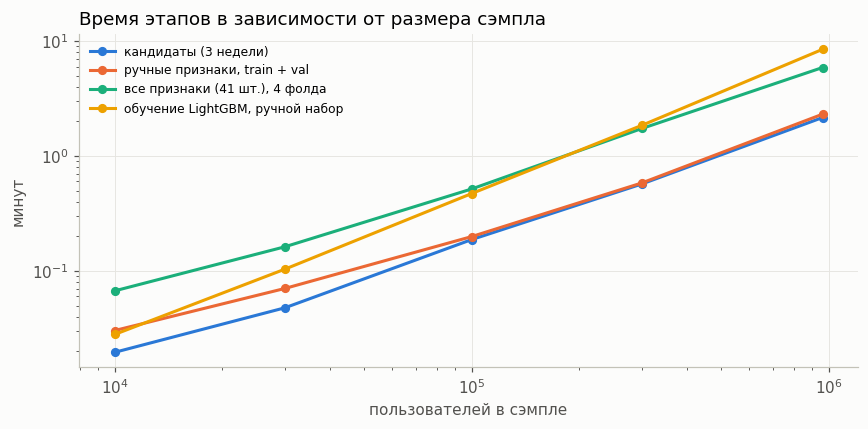

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
users = [r['пользователей'] for r in results]
stages = list(results[0]['время, с'])
for stage, color in zip(stages, COLORS):
    ax.plot(users, [r['время, с'][stage] / 60 for r in results], marker='o', linewidth=2, markersize=5, color=color, label=stage)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('пользователей в сэмпле')
ax.set_ylabel('минут')
ax.set_title('Время этапов в зависимости от размера сэмпла', loc='left')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

### Сохраняются ли выводы

In [6]:
gen_rows = []
for r in results:
    row = {'пользователей': r['пользователей'], 'в тесте': r['пользователей в тесте'],
           'NDCG ручных': r['ndcg']['ручные']}
    for name, (d, lo, hi) in r['delta'].items():
        row[f'Δ {name}'] = f'{d:+.4f} [{lo:+.4f}, {hi:+.4f}]'
    gen_rows.append(row)
pl.DataFrame(gen_rows)

пользователей,в тесте,NDCG ручных,Δ только базовые,"Δ жадный, случайный пул","Δ жадный, пул от LLM",Δ ручные + жадный (LLM)
i64,i64,f64,str,str,str,str
10000,1154,0.135411,"""-0.0029 [-0.0106, +0.0051]""","""+0.0014 [-0.0049, +0.0077]""","""+0.0015 [-0.0049, +0.0082]""","""-0.0036 [-0.0092, +0.0021]"""
30000,3422,0.153023,"""-0.0029 [-0.0066, +0.0009]""","""+0.0021 [-0.0011, +0.0051]""","""+0.0010 [-0.0023, +0.0042]""","""+0.0035 [+0.0007, +0.0062]"""
100000,11425,0.152788,"""-0.0063 [-0.0081, -0.0045]""","""-0.0015 [-0.0030, +0.0001]""","""-0.0032 [-0.0048, -0.0015]""","""+0.0014 [+0.0001, +0.0026]"""
300000,34727,0.153493,"""-0.0077 [-0.0087, -0.0068]""","""+0.0004 [-0.0005, +0.0012]""","""-0.0026 [-0.0035, -0.0017]""","""+0.0010 [+0.0004, +0.0016]"""
962179,111240,0.155567,"""-0.0096 [-0.0102, -0.0091]""","""+0.0005 [-0.0000, +0.0010]""","""-0.0021 [-0.0026, -0.0016]""","""+0.0001 [-0.0003, +0.0004]"""


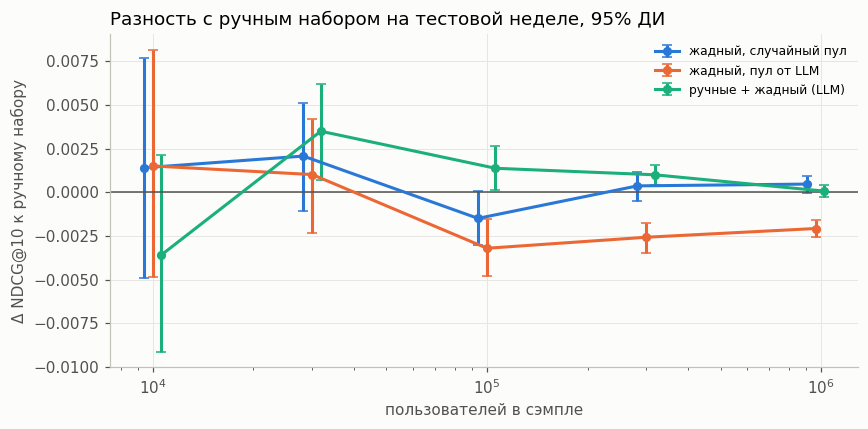

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
names_g = ['жадный, случайный пул', 'жадный, пул от LLM', 'ручные + жадный (LLM)']
for k, (name, color) in enumerate(zip(names_g, COLORS)):
    x = np.array(users) * (1 + 0.06 * (k - 1))         # небольшой сдвиг, чтобы интервалы не перекрывались
    d = np.array([r['delta'][name] for r in results])
    ax.errorbar(x, d[:, 0], yerr=[d[:, 0] - d[:, 1], d[:, 2] - d[:, 0]], color=color, marker='o',
                markersize=5, linewidth=2, capsize=3, label=name)
ax.axhline(0, color='#52514e', linewidth=1)
ax.set_xscale('log')
ax.set_xlabel('пользователей в сэмпле')
ax.set_ylabel('Δ NDCG@10 к ручному набору')
ax.set_title('Разность с ручным набором на тестовой неделе, 95% ДИ', loc='left')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Время и память.** Расчёт кандидатов и признаков растёт линейно: показатель степени по размеру выборки 0.94–1.04, то есть в 76–110 раз при росте числа пользователей в 96 раз. Обучение LightGBM растёт чуть быстрее линейного (показатель 1.25, в 302 раза): на полном датасете одно обучение ручного набора занимает 8.5 минуты. Весь протокол (кандидаты трёх недель, 41 признак на четырёх фолдах, пять моделей, оценка) занял 0.4 минуты на 10 тыс. пользователей, 4.2 минуты на 100 тыс. и 80 минут на всех 962 тыс. Память процесса растёт медленнее числа пользователей (показатель около 0.5–0.65): пик 0.9 ГБ на 10 тыс. и 17.6 ГБ на полном датасете. Полный датасет не помещается на ноутбуке с 8 ГБ, но помещается в 30 ГБ Kaggle. Узкое место масштабирования здесь — обучение модели и матрицы признаков в памяти, а не расчёт агрегатов; для промышленных объёмов признаки пришлось бы считать и хранить частями.

**Работают ли наборы, найденные на 100 тыс. пользователей, на других объёмах.** Поиск шёл на сэмпле 100 тыс. пользователей, здесь те же наборы применены к другим размерам, в том числе ко всему датасету, где 90% пользователей поиск не видел. Разность NDCG@10 с ручным набором на тестовой неделе 16.08:

- **Только базовые признаки** хуже ручного на всех размерах, и разрыв растёт вместе с выборкой: −0.0029 на 10 тыс., −0.0096 [−0.0102, −0.0091] на полном датасете. На малых выборках польза агрегатов просто не видна из-за шума.
- **LLM-набор** хуже ручного начиная со 100 тыс.: интервалы не содержат ноль на 100 тыс., 300 тыс. и на полном датасете (−0.0021 [−0.0026, −0.0016]).
- **Жадный набор со случайным пулом** на уровне ручного: +0.0005 [−0.0000, +0.0010] на полном датасете, при этом в нём 6 признаков вместо 29.
- **Объединение ручных и найденных признаков:** +0.0035 на 30 тыс., +0.0014 на 100 тыс., +0.0010 на 300 тыс. и +0.0001 [−0.0003, +0.0004] на полном датасете. Прирост убывает с ростом выборки и на всех пользователях исчезает. Вероятное объяснение, которое здесь не проверялось: найденные признаки подобраны под пользователей и недели поискового сэмпла, а на остальных пользователях дают то же качество, что ручные.

На выборках в 10 и 30 тыс. пользователей в тесте 1 154 и 3 422 человека, интервалы шире 0.01, и почти ничего не различить. Эксперименты на малых сэмплах, которыми мы пользовались при поиске, нужно читать осторожно.

Точка 100 тыс. здесь не совпадает с основным ноутбуком: например, у жадного набора −0.0015 против +0.0007. Это та же случайность обучения, которая измерена в разделе 6.6 основного ноутбука.